# RT-DETR-L (Ultralytics) — Training

Fine-tunes the COCO-pretrained `rtdetr-l.pt` on Construction-PPE. The test-set evaluation is in
[`rtdetr_l_eval.ipynb`](rtdetr_l_eval.ipynb).

| Setting | Value |
|---|---|
| Input size | 640×640 |
| Optimizer, LR schedule, loss | Ultralytics defaults for this model (`optimizer="auto"`) |
| Batch size | 8 |
| Epochs | `EPOCH_BUDGET` = 10 (shared scratch-run budget) |
| Checkpoint | best validation fitness → `models/rtdetr_l/weights/best.pt` |

> **Scratch run.** The shared `EPOCH_BUDGET` (`experiment.py`) is **10** so the notebook runs end to end quickly. For
> the actual runs, change this to early stopping: pass a larger `epochs` budget plus `patience=<N>` to `model.train`, which stops once validation fitness has not improved for N epochs.

**Data augmentation** is shared by all four models (`ppe_detection_evaluation.dataset.augmentations`). `SharedAugmentation` reseeds
from `(SEED, epoch, image name)`, so every model trains on exactly the same examples; only the order within an epoch
differs.

| # | Augmentation | Parameters | p |
|---|---|---|---|
| A1 | Horizontal flip | — | 0.5 |
| A2 | Scale + translate | scale 0.75–1.25, translate ±10 %, gray fill 114 | 1.0 |
| A3 | Colour jitter | brightness ±0.4, contrast ±0.3, saturation ±0.5, hue ±0.015 | 1.0 |
| A4 | One of blur / noise / JPEG | σ 0.1–1.5; σ 0.02–0.06; quality 40–90 | 0.25 |

Every image is first resized to 640×640. Boxes keeping less than 40 % of their area, or narrower than 3 px, are dropped.
Validation and test images are only resized.

Ultralytics' own augmentation (mosaic, HSV, perspective, flips and its built-in Albumentations) is **bypassed**:
`SharedAugmentationRTDETRTrainer` trains on a dataset whose `build_transforms` (Ultralytics' augmentation hook) produces each example
through the same `load_training_example` as the torchvision models,
followed only by Ultralytics' `Format`. The built-in augmentation arguments
are also zeroed (`DISABLE_BUILTIN_AUGMENTATION` in `ultralytics_adapter.py`), so the run's `args.yaml` records it.

In [1]:
import csv
import os

%matplotlib inline
import matplotlib.pyplot as plt
from ultralytics import RTDETR

from ppe_detection_evaluation.dataset.augmentations import SharedAugmentation
from ppe_detection_evaluation.dataset.core import check_dataset, class_box_stats, download_dataset, verify_same_examples
from ppe_detection_evaluation.dataset.ultralytics_adapter import (
    DISABLE_BUILTIN_AUGMENTATION,
    SharedAugmentationRTDETRTrainer,
    build_train_dataset,
    write_ultralytics_yaml,
)
from ppe_detection_evaluation.experiment import DATA_ROOT, EPOCH_BUDGET, IMAGE_SIZE, MODELS_DIR, PRETRAINED_DIR, SEED
from ppe_detection_evaluation.utilities.visualize import plot_examples

## Hyperparameters

Everything tunable for this model is set in the next cell. `SEED` and `EPOCH_BUDGET` are shared by all four notebooks
(`experiment.py`): the seed fixes the augmented examples and the budget caps every model at the same number of
epochs. Batch size and optimizer settings are chosen per model.

In [ ]:
# EPOCH_BUDGET is the shared scratch-run budget (10, experiment.py). For the actual runs, raise it there and
# pass patience=<N> to model.train (see the note at the top).
EPOCHS = EPOCH_BUDGET
BATCH_SIZE = 8    # RT-DETR-L is memory hungry; batch=-1 lets Ultralytics pick the largest that fits
# Optimizer, LR schedule and loss weights stay at Ultralytics' defaults (optimizer="auto").

In [ ]:
# SEED, DATA_ROOT and the model folders come from experiment.py and are shared by all four notebooks.
PROJECT_DIR = MODELS_DIR  # the run lands in models/<RUN_NAME>/ (weights/, curves, results.csv)
RUN_NAME = "rtdetr_l"
print(f"Epochs: {EPOCHS} | Batch: {BATCH_SIZE} | Image size: {IMAGE_SIZE}")

## 1. Dataset

[Ultralytics Construction-PPE](https://docs.ultralytics.com/datasets/detect/construction-ppe/): 11 classes, five
present/absent PPE pairs (helmet, vest, goggles, gloves, boots) plus `Person`. `download_dataset` is a no-op once
`data/construction-ppe` exists, so all four notebooks share one copy.

If more than ~15 % of `goggles` / `no_goggle` boxes (the smallest PPE) are under 16 px, raise the minimum of
`SCALE_RANGE` in `augmentations.py` from 0.75 to 0.85, for every model.

In [3]:
download_dataset(DATA_ROOT)
splits = check_dataset(DATA_ROOT)  # raises if the class order differs from DEFAULT_CLASS_NAMES
print("Images per split:", splits)

print(f"\n{'Class':<10} {'Boxes':>6} {'<16 px':>7}")
for name, s in class_box_stats(DATA_ROOT, "train").items():
    print(f"{name:<10} {s['count']:>6} {s['under_16px']:>7.1%}")

# Ultralytics resolves relative paths in data.yaml against the CWD, so write one with absolute paths.
data_yaml = write_ultralytics_yaml(DATA_ROOT)

Images per split: {'train': 1132, 'valid': 143, 'test': 141}

Class       Boxes  <16 px
helmet       1341    1.0%
gloves       1146    0.5%
vest         1269    0.1%
boots        1235    0.2%
goggles       419    2.6%
no_vest       651    0.8%
Person       1770    0.0%
no_helmet     400    0.2%
no_goggle     337   12.5%
no_gloves     442    1.4%
no_boots       88    0.0%


## 2. Training data

The training dataset below is built exactly as the trainer builds it, so the preview and the check show what the model
is actually fed. `seed=SEED` is also the shared augmentation seed (the dataset reads `args.seed`), and a callback
restarts the persistent DataLoader workers each epoch so they pick up the new epoch number.

In [4]:
train_ds = build_train_dataset(data_yaml, seed=SEED, rtdetr=True)
print(f"Train: {len(train_ds)} images")

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4310.9±900.7 MB/s, size: 80.3 KB)
train: Scanning /home/llravelo/Documents/projects/42177-image-processing-ppe-detection/data/construction-ppe/train/labels.cache... 1132 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1132/1132 395.7Mit/s 0.0s
train: /home/llravelo/Documents/projects/42177-image-processing-ppe-detection/data/construction-ppe/train/images/image187.jpg: 1 duplicate labels removed
Train: 1132 images


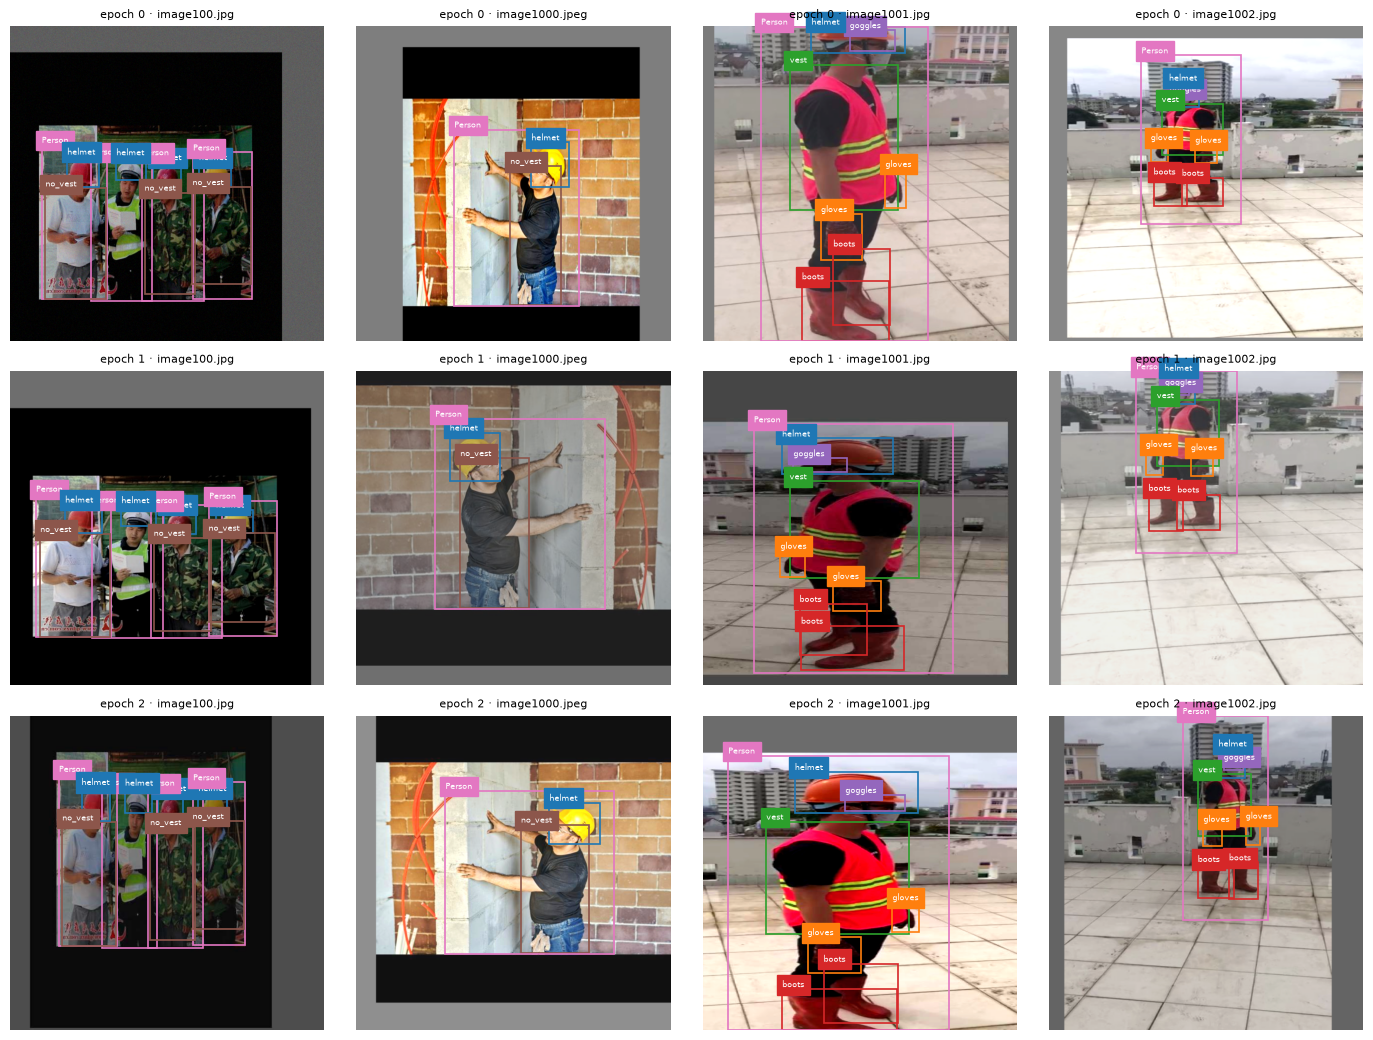

In [5]:
# Four training images (columns) as the model sees them in epochs 0–2 (rows)
examples, titles = [], []
for epoch in range(3):
    train_ds.epoch = epoch
    for i in range(4):
        path, image, boxes, labels = train_ds.as_raw_example(i)
        examples.append((image, boxes, labels))
        titles.append(f"epoch {epoch} · {os.path.basename(path)[:20]}")
train_ds.epoch = 0
plot_examples(examples, titles);

**Check: same examples as the other models.** `verify_same_examples` pulls samples through this model's own
training dataset and asserts they equal the shared pipeline's output. The fingerprints must be identical in all four
training notebooks.

In [6]:
augmentation = SharedAugmentation(seed=SEED)
fingerprints = {}
for epoch in (0, 1):
    train_ds.epoch = epoch
    fingerprints[epoch] = verify_same_examples(train_ds.as_raw_example, range(32), augmentation, epoch)
train_ds.epoch = 0
fingerprints

{0: '25ed5a7353bba7b7', 1: '7d41d3f801e1b393'}

## 3. Model

COCO-pretrained RT-DETR-L. When training starts, Ultralytics rebuilds the model with the dataset's 11 classes and
copies every pretrained tensor whose name and shape match. Only the class-score layers (one for the encoder, one per
decoder layer) and the denoising label embedding start fresh; the backbone, encoder and box heads keep their COCO
weights. RT-DETR has no NMS: the evaluation keeps queries scoring at least 0.001, at most 100 per image.

In [7]:
model = RTDETR(PRETRAINED_DIR / "rtdetr-l.pt")  # COCO weights, downloaded here on first use
model.info()

rt-detr-l summary: 449 layers, 32,970,476 parameters, 0 gradients, 110.2 GFLOPs


(449, 32970476, 0, 110.2435104)

## 4. Training

After training starts, open `train_batch0.jpg` in the run directory: it must show single images with mild scale,
colour and blur/noise changes, and **no** mosaic collages or grayscale frames.

In [8]:
model.train(
    trainer=SharedAugmentationRTDETRTrainer,
    data=str(data_yaml),
    epochs=EPOCHS,
    batch=BATCH_SIZE,
    imgsz=IMAGE_SIZE,
    seed=SEED,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True,
    **DISABLE_BUILTIN_AUGMENTATION,
)

save_dir = model.trainer.save_dir
print(f"\nResults saved to: {save_dir}")

Ultralytics 8.4.178 🚀 Python-3.13.13 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4070, 11872MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/llravelo/Documents/projects/42177-image-processing-ppe-detection/data/construction-ppe/ultralytics.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mos

[W1016 12:40:22.140274254 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 16777216 bytes (free: 63176704, total: 12449021952).
[W1016 12:40:22.140344664 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 16777216 bytes (free: 63176704, total: 12449021952).


train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3882.9±3394.8 MB/s, size: 249.5 KB)
train: Scanning /home/llravelo/Documents/projects/42177-image-processing-ppe-detection/data/construction-ppe/train/labels.cache... 1132 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1132/1132 791.3Mit/s 0.0s
train: /home/llravelo/Documents/projects/42177-image-processing-ppe-detection/data/construction-ppe/train/images/image187.jpg: 1 duplicate labels removed
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5674.4±2487.5 MB/s, size: 113.1 KB)
val: Scanning /home/llravelo/Documents/projects/42177-image-processing-ppe-detection/data/construction-ppe/valid/labels.cache... 143 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 143/143 100.0Mit/s 0.0s
: 0% ──────────── 0/142  2.2s

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


[W1016 12:40:23.494044909 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 2097152 bytes (free: 54394880, total: 12449021952).


       1/10      3.32G      1.477      10.73     0.8273         29        640: 0% ──────────── 0/283  2.9s

...

       8/10      3.76G     0.5146     0.4917     0.2816         29        640: 100% ━━━━━━━━━━━━ 283/283 7.0it/s 40.7s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 14.4it/s 1.3s0.1s
                   all        143       1172      0.637      0.599      0.601      0.299

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       9/10      3.76G      0.469     0.4966     0.2766         54        640: 0% ──────────── 1/283 2.2it/s 1.0s<2:08

/home/llravelo/Documents/projects/42177-image-processing-ppe-detection/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       9/10      3.76G     0.4999     0.4727     0.2702         41        640: 100% ━━━━━━━━━━━━ 283/283 7.2it/s 39.5s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 14.7it/s 1.2s0.1s
                   all        143       1172      0.711      0.606      0.612        0.3

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      10/10      3.76G     0.5097     0.4528     0.2788         50        640: 0% ──────────── 1/283 2.2it/s 1.0s<2:09

/home/llravelo/Documents/projects/42177-image-processing-ppe-detection/.venv/lib/python3.13/site-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      10/10      3.76G     0.4908     0.4608     0.2585         42        640: 100% ━━━━━━━━━━━━ 283/283 7.2it/s 39.4s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 14.7it/s 1.2s0.1s
                   all        143       1172      0.697      0.606      0.615      0.301

10 epochs completed in 0.119 hours.
Optimizer stripped from /home/llravelo/Documents/projects/42177-image-processing-ppe-detection/results/runs/rtdetr_l/weights/last.pt, 66.3MB
Optimizer stripped from /home/llravelo/Documents/projects/42177-image-processing-ppe-detection/results/runs/rtdetr_l/weights/best.pt, 66.3MB

Validating /home/llravelo/Documents/projects/42177-image-processing-ppe-detection/results/runs/rtdetr_l/weights/best.pt...
Ultralytics 8.4.178 🚀 Python-3.13.13 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4070, 11872MiB)
rt-detr-l summary (fused): 315 layers, 32,006,345 parameters, 0 gradients, 105.4 GFLOPs
                 Class   

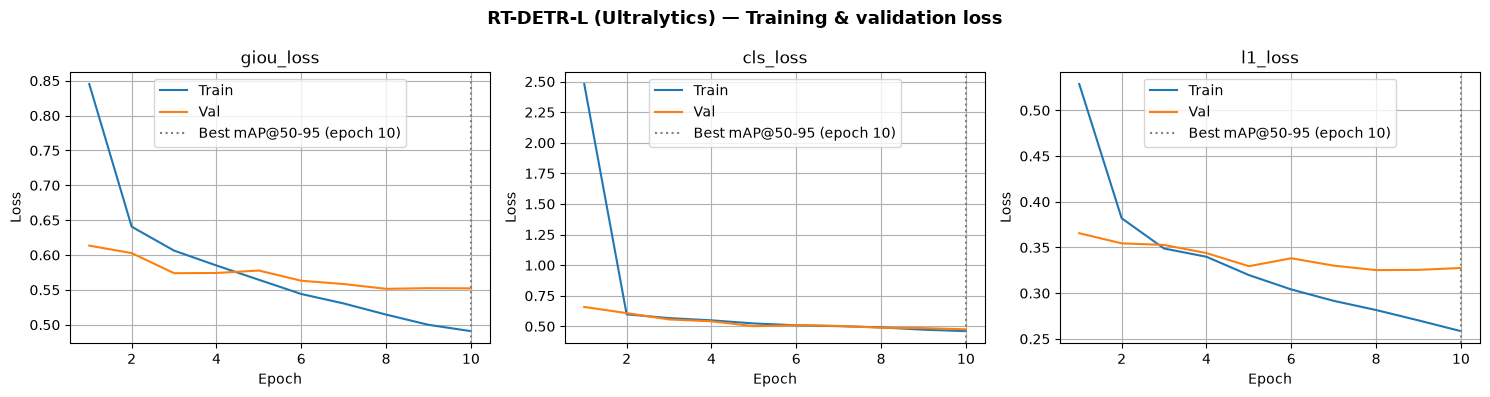

In [9]:
with open(save_dir / "results.csv") as f:
    rows = list(csv.DictReader(f))
history = {key.strip(): [float(row[key]) for row in rows] for key in rows[0]}
epochs_x = history["epoch"]
best_epoch = epochs_x[max(range(len(rows)), key=lambda i: history["metrics/mAP50-95(B)"][i])]

# Loss terms differ per model (e.g. box/cls/l1 for YOLO26, giou/cls/l1 for RT-DETR), so read them from the CSV.
losses = [key.removeprefix("train/") for key in history if key.startswith("train/")]
fig, axes = plt.subplots(1, len(losses), figsize=(5 * len(losses), 4))
for ax, loss in zip(axes, losses):
    ax.plot(epochs_x, history[f"train/{loss}"], label="Train")
    ax.plot(epochs_x, history[f"val/{loss}"], label="Val")
    ax.axvline(best_epoch, color="grey", linestyle=":", lw=1.5, label=f"Best mAP@50-95 (epoch {best_epoch:.0f})")
    ax.set(xlabel="Epoch", ylabel="Loss", title=loss)
    ax.legend()
    ax.grid(True)
plt.suptitle("RT-DETR-L (Ultralytics) — Training & validation loss", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(save_dir / "loss_curves.png", dpi=150)
plt.show()

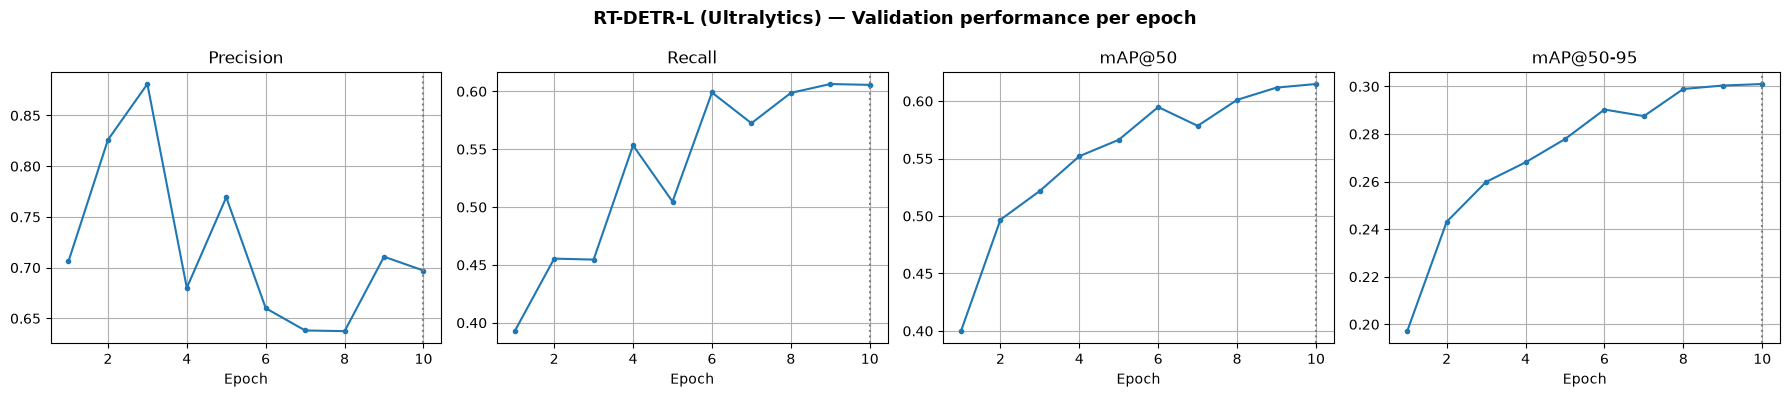

In [10]:
metrics = [
    ("metrics/precision(B)", "Precision"),
    ("metrics/recall(B)", "Recall"),
    ("metrics/mAP50(B)", "mAP@50"),
    ("metrics/mAP50-95(B)", "mAP@50-95"),
]
fig, axes = plt.subplots(1, len(metrics), figsize=(18, 4))
for ax, (key, label) in zip(axes, metrics):
    ax.plot(epochs_x, history[key], marker="o", markersize=3)
    ax.axvline(best_epoch, color="grey", linestyle=":", lw=1.5)
    ax.set(xlabel="Epoch", title=label)
    ax.grid(True)
plt.suptitle("RT-DETR-L (Ultralytics) — Validation performance per epoch", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(save_dir / "val_metrics.png", dpi=150)
plt.show()

Next: evaluate `models/rtdetr_l/weights/best.pt` on the test split with [`rtdetr_l_eval.ipynb`](rtdetr_l_eval.ipynb).